# Домашнє завдання до модуля «Алгоритми навчання з вчителем Ч.2»

Мета: коректно розділити набір даних Rain in Australia за історичним принципом (тестова вибірка — останній рік спостережень) та оцінити, як це вплине на метрики логістичної регресії порівняно з базовою моделлю з конспекту.

### 1. Імпорт необхідних пакетів

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

Набори даних беремо з локальної папки репозиторію курсу, а якщо її немає (наприклад, під час запуску в Google Colab) — безпосередньо з GitHub.

In [2]:
DATA_DIR = Path('../datasets')

DATA_URL = ('https://raw.githubusercontent.com/goitacademy/'
            'MACHINE-LEARNING-NEO/main/')


def data_path(filename, folder='datasets'):
    local = DATA_DIR / filename
    return local if local.exists() else DATA_URL + folder + '/' + filename

### 2. Завантаження набору даних Rain in Australia

In [3]:
data = pd.read_csv(data_path('mod_03_topic_05_weather_data.csv.gz'))
data.shape

(145460, 23)

In [4]:
data.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


### 3.1. Видалення ознак з великою кількістю пропущених значень

Як і в конспекті, відкидаємо колонки, у яких частка пропусків перевищує 0.35, а також спостереження без цільової мітки.

In [5]:
data.isna().mean().sort_values(ascending=False).head(8)

Sunshine       0.480098
Evaporation    0.431665
Cloud3pm       0.408071
Cloud9am       0.384216
Pressure9am    0.103568
Pressure3pm    0.103314
WindDir9am     0.072639
WindGustDir    0.070989
dtype: float64

In [6]:
data = data[data.columns[data.isna().mean().lt(0.35)]]

data = data.dropna(subset='RainTomorrow')

data.shape

(142193, 19)

### 3.2. Підмножини з числовими та категоріальними ознаками

In [7]:
data_num = data.select_dtypes(include=np.number)
data_cat = data.select_dtypes(include='object')

data_cat.columns

Index(['Date', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm',
       'RainToday', 'RainTomorrow'],
      dtype='object')

### 3.3. Обробка часової ознаки

Змінюємо тип колонки `Date` на `datetime` і створюємо на її основі додаткові колонки `Year` та `Month`.

In [8]:
data_cat['Date'] = pd.to_datetime(data['Date'])

data_cat[['Year', 'Month']] = (data_cat['Date']
                               .apply(lambda x:
                                      pd.Series([x.year, x.month])))

data_cat.drop('Date', axis=1, inplace=True)

data_cat[['Year', 'Month']] = data_cat[['Year', 'Month']].astype(str)

data_cat[['Year', 'Month']].head()

,Year,Month
0,2008,12
1,2008,12
2,2008,12
3,2008,12
4,2008,12


### 3.4. Перенесення ознаки Year до числових

«Рік» надалі обробляємо як числову ознаку, а «місяць» року залишаємо категоріальною.

In [9]:
data_num['Year'] = data_cat.pop('Year').astype(int)

data_num['Year'].value_counts().sort_index()

Year
2007       61
2008     2246
2009    16595
2010    16419
2011    15126
2012    15044
2013    16097
2014    17400
2015    17231
2016    17508
2017     8466
Name: count, dtype: int64

### 3.5. Розбиття за історичним принципом

До тестової вибірки відносимо всі об'єкти з останнім (максимальним) роком спостережень, решту використовуємо для навчання. Для розбиття використовуємо булеву індексацію.

In [10]:
test_mask = data_num['Year'].eq(data_num['Year'].max())

X_train_num, X_test_num = data_num[~test_mask], data_num[test_mask]

X_train_cat = data_cat.drop('RainTomorrow', axis=1)[~test_mask]
X_test_cat = data_cat.drop('RainTomorrow', axis=1)[test_mask]

y_train, y_test = data['RainTomorrow'][~test_mask], data['RainTomorrow'][test_mask]

print(f'train: {len(y_train)} | test: {len(y_test)}')

train: 133727 | test: 8466


### 4. Відновлення пропущених значень

In [11]:
num_imputer = SimpleImputer().set_output(transform='pandas')
X_train_num = num_imputer.fit_transform(X_train_num)
X_test_num = num_imputer.transform(X_test_num)

cat_imputer = SimpleImputer(
    strategy='most_frequent').set_output(transform='pandas')
X_train_cat = cat_imputer.fit_transform(X_train_cat)
X_test_cat = cat_imputer.transform(X_test_cat)

pd.concat([X_train_num, X_test_num]).isna().sum().sum()

np.int64(0)

### 5. Нормалізація числових ознак

In [12]:
scaler = StandardScaler().set_output(transform='pandas')

X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

### 6. Кодування категоріальних ознак

In [13]:
encoder = (OneHotEncoder(drop='if_binary',
                         sparse_output=False)
           .set_output(transform='pandas'))

X_train_cat = encoder.fit_transform(X_train_cat)
X_test_cat = encoder.transform(X_test_cat)

X_train_cat.shape

(133727, 110)

### 7. Об'єднання підмножин і побудова моделі

In [14]:
X_train = pd.concat([X_train_num, X_train_cat], axis=1)
X_test = pd.concat([X_test_num, X_test_cat], axis=1)

X_train.shape

(133727, 123)

Проведемо невеликий експеримент із гіперпараметром `solver`, щоб перевірити, чи впливає вибір алгоритму оптимізації на якість прогнозів.

In [15]:
for solver in ['liblinear', 'lbfgs', 'saga']:
    mod = (LogisticRegression(solver=solver,
                              class_weight='balanced',
                              max_iter=1000,
                              random_state=42)
           .fit(X_train, y_train))
    prd = mod.predict(X_test)
    rep = classification_report(y_test, prd, output_dict=True)
    print(f"{solver:>10} | f1 (Yes): {rep['Yes']['f1-score']:.3f} "
          f"| accuracy: {rep['accuracy']:.3f}")

 liblinear | f1 (Yes): 0.598 | accuracy: 0.798


/private/tmp/claude-501/-Users-faridjafarli-GitHub-goit-hw-machine-learning-fundamentals-goit-hw-01/7abab42e-2eb9-43b9-866a-7510511486b5/scratchpad/venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


     lbfgs | f1 (Yes): 0.597 | accuracy: 0.798


      saga | f1 (Yes): 0.598 | accuracy: 0.798


Різні solver'и дають однаковий результат, тому залишаємо `liblinear`, як у конспекті.

In [16]:
clf = (LogisticRegression(solver='liblinear',
                          class_weight='balanced',
                          random_state=42)
       .fit(X_train, y_train))

pred = clf.predict(X_test)

### 8. Оцінка моделі й порівняння з базовою

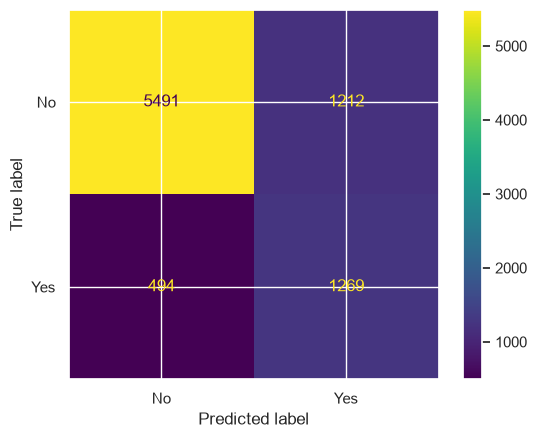

In [17]:
sns.set_theme()

ConfusionMatrixDisplay.from_predictions(y_test, pred)

plt.show()

In [18]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

          No       0.92      0.82      0.87      6703
         Yes       0.51      0.72      0.60      1763

    accuracy                           0.80      8466
   macro avg       0.71      0.77      0.73      8466
weighted avg       0.83      0.80      0.81      8466



**Порівняння метрик**

| Метрика (клас Yes) | Базова модель (випадкове розбиття) | Нова модель (розбиття за роками) |
|---|---|---|
| precision | 0.51 | 0.51 |
| recall | 0.76 | 0.72 |
| f1-score | 0.61 | 0.60 |
| accuracy | 0.79 | 0.80 |

**Висновки**

1. Після коректного розбиття набору даних за історичним принципом метрики моделі майже не змінилися: precision залишилась на рівні 0.51, recall зменшився з 0.76 до 0.72, f1-score — з 0.61 до 0.60, а загальна accuracy навіть трохи зросла (0.79 → 0.80).
2. Це хороший результат: він означає, що базова модель не була «завищеною» через витік інформації про майбутнє. Модель справді вловлює зв'язок між погодними показниками поточного дня і дощем наступного дня, а не просто «запам'ятовує» конкретні дати з тестової вибірки.
3. Невелике зниження recall очікуване, оскільки тепер модель прогнозує на періоді, жодного дня з якого вона не бачила під час навчання. Саме така оцінка є об'єктивною з точки зору реального використання моделі, коли прогноз завжди робиться на «майбутніх» даних.
4. Перенесення ознаки `Year` до числових дозволяє моделі екстраполювати її значення на нові роки. Якби рік залишався категоріальною ознакою, то для тестового року onehot-кодування створило б колонку, якої модель не бачила під час навчання, і ця інформація була б для неї беззмістовною.
5. Експеримент із гіперпараметром `solver` показав, що для цієї задачі вибір алгоритму оптимізації не впливає на результат — усі три варіанти збіглися до однакового розв'язку.
6. Практичний зміст метрик залишився таким самим, як у конспекті: модель виявляє приблизно 7 із 10 дощових днів, але приблизно у половині випадків, коли вона прогнозує дощ, він не відбувається.